In [29]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [30]:
#Importar base de dados 

df = pd.read_csv('student_habits_performance.csv')

df.head(5)

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   object 
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   object 
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   object 
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   object 
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    object 
 12  internet_quality               1000 non-null   ob

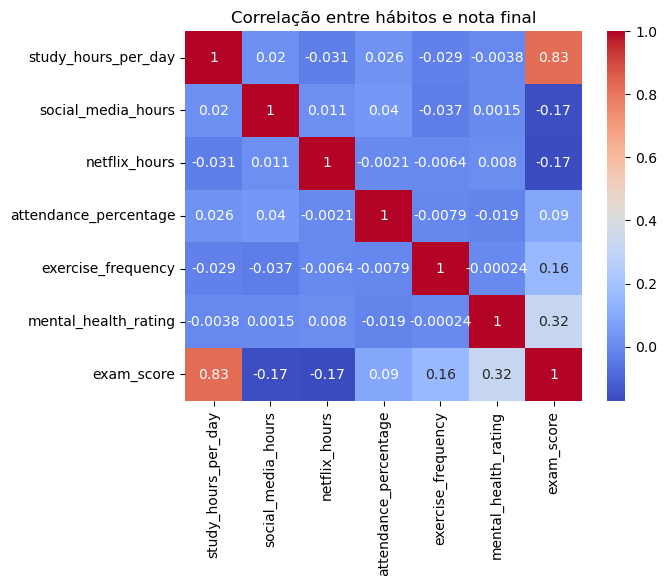

In [32]:
#HEATMAP: 

cols = [
    'study_hours_per_day',
    'social_media_hours',
    'netflix_hours',
    'attendance_percentage',
    'exercise_frequency',
    'mental_health_rating',
    'exam_score',
]

sns.heatmap(df[cols].corr(), annot = True, cmap = 'coolwarm') 
plt.title('Correlação entre hábitos e nota final')
plt.show()

📊 Análise do Heatmap

O heatmap mostra a correlação entre as variáveis.

Correlação positiva: quando uma variável aumenta, a outra tende a aumentar.

Correlação negativa: quando uma variável aumenta, a outra tende a diminuir.

Nosso foco é a variável exam_score.

--------------------------------------------------------------------------------------------------------------------------------------

🔍 Principais observações


Correlações positivas:
attendance: 0.83
mental_health_rating: 0.32
➡️ Alunos com maior frequência e melhor saúde mental tendem a ter notas mais altas.



Correlações negativas:
social_media_hours: -0.17
netflix_hours: -0.17
➡️ Mais tempo gasto em redes sociais e Netflix pode estar associado a notas menores.

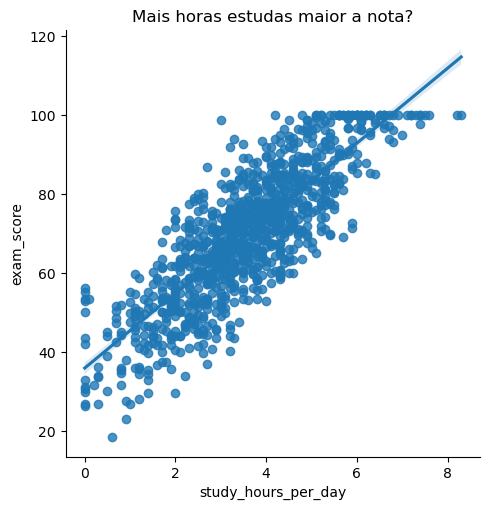

In [33]:
# Com base no heatmap podemos obsevar a seguinte hipótese: quanto maior o tempo de estudo do aluno melhor é a nota 
# Será que essa hipótese é verdadeira mesmo? 

sns.lmplot(data=df, x = 'study_hours_per_day', y = 'exam_score')
plt.title('Mais horas estudas maior a nota?')
plt.show()



📈 Análise do Gráfico de Dispersão


--> O gráfico de dispersão mostra uma tendência positiva entre study_hours_per_day e exam_score.



➡️ De maneira geral, quanto maior o número de horas estudadas por dia, maiores tendem a ser as notas dos alunos.


Essa tendência sugere que o aumento do tempo dedicado aos estudos está associado a um melhor desempenho acadêmico.

In [34]:
# Mas, por que quem estuda >5h tem notas melhores do que pessoas <2h, quão grande é essa diferença? Vamos descobrir pela média
# O resultado só afirma cada vez mais que quanto mais horas estudads maior a média 
# Podemos concluir que é o fator mais determinante para os alunos tirar uma boa nota é estudar mais horas 

filtro_estudo_baixo = df['study_hours_per_day'] < 2
filtro_estudo_alto = df['study_hours_per_day'] > 5 

cluster_estudo_baixo = df[filtro_estudo_baixo]['exam_score']
cluster_estudo_alto = df[filtro_estudo_alto]['exam_score']

print('A média de estudo de menos de 2 horas foi de', cluster_estudo_baixo.mean())
print('A média de estudo de menos de 5 horas foi de', cluster_estudo_alto.mean()) 

A média de estudo de menos de 2 horas foi de 45.56390977443609
A média de estudo de menos de 5 horas foi de 90.79419354838709


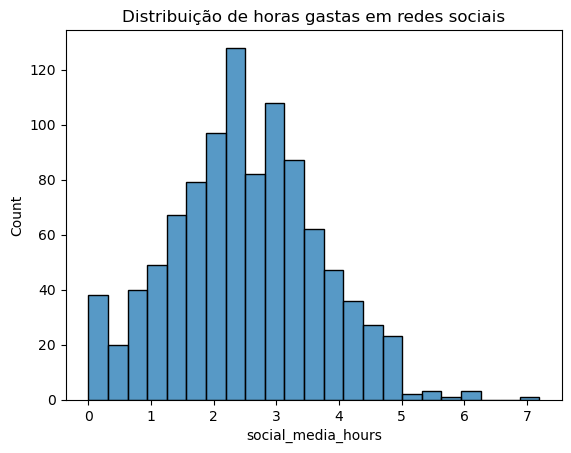

In [36]:
# Distribuição de quantas horas ficam nas redes sociais 

sns.histplot(data=df, x='social_media_hours')
plt.title('Distribuição de horas gastas em redes sociais')
plt.show()